# Preanalysis

## Data Importing

In [470]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings

plt.style.use("seaborn-v0_8-whitegrid")
filterwarnings("ignore")

In [471]:
price_history_electricity = pd.read_csv('data/Price History_Electricity.csv', sep=';', decimal=',')
price_history_gas_monthly1 = pd.read_csv('data/Price History_Gas_Monthly1.csv')
price_history_carbon = pd.read_csv('data/Price History_Carbon.csv')
price_history_coal = pd.read_csv('data/Price History_Coal.csv')
price_history_oil = pd.read_csv('data/Price History_Oil.csv')
price_history_EURUSD = pd.read_csv('data/Price History_EUR:USD.csv')
price_history_EURGPD = pd.read_csv('data/Price History_EUR:GPD.csv')

In [472]:
# hourly → daily averaging for all electricity markets
_elec_raw = price_history_electricity.copy()
_elec_raw['ts'] = pd.to_datetime(_elec_raw['Datum von'], dayfirst=True)
_elec_raw['date'] = _elec_raw['ts'].dt.normalize()

_elec_cols = {
    'Deutschland/Luxemburg [€/MWh] Berechnete Auflösungen': 'price_history_electricity',
    'Frankreich [€/MWh] Berechnete Auflösungen': 'price_history_elec_fr',
    'Niederlande [€/MWh] Berechnete Auflösungen': 'price_history_elec_nl',
}

for col, var_name in _elec_cols.items():
    _elec_raw[col] = pd.to_numeric(
        _elec_raw[col]
        .astype(str)
        .str.replace(',', '.', regex=False),
        errors='coerce'
    )

_elec_daily = _elec_raw.groupby('date', as_index=False)[list(_elec_cols.keys())].mean()

for col, var_name in _elec_cols.items():
    globals()[var_name] = _elec_daily[['date', col]].rename(columns={col: 'price'})

price_history_electricity.head()

,date,price
0,2021-01-01,48.398333
1,2021-01-02,50.562500
2,2021-01-03,38.622500
3,2021-01-04,48.017917
4,2021-01-05,55.337083


In [473]:
# handle commodities
def _handle_commodities(df):
    df['Exchange Date'] = pd.to_datetime(df['Exchange Date'], dayfirst=True)
    df['date'] = df['Exchange Date']
    df['price'] = df['Close']
    return df[['date', 'price']]

# handle forex
def _handle_forex(df):
    df['Exchange Date'] = pd.to_datetime(df['Exchange Date'], dayfirst=True)
    df['date'] = df['Exchange Date']
    df['price'] = (df['Bid'] + df['Ask']) / 2
    return df[['date', 'price']]

In [474]:
price_history_gas_monthly1 = _handle_commodities(price_history_gas_monthly1)
price_history_carbon = _handle_commodities(price_history_carbon)
price_history_coal = _handle_commodities(price_history_coal)
price_history_oil = _handle_commodities(price_history_oil)
price_history_EURUSD = _handle_forex(price_history_EURUSD)
price_history_EURGPD = _handle_forex(price_history_EURGPD)

In [475]:
print(f'Electricity:\n{price_history_electricity.isna().sum()}')
print(f'Gas Monthly1:\n{price_history_gas_monthly1.isna().sum()}')
print(f'Carbon:\n{price_history_carbon.isna().sum()}')
print(f'Coal:\n{price_history_coal.isna().sum()}')
print(f'Oil:\n{price_history_oil.isna().sum()}')
print(f'Elec FR:\n{price_history_elec_fr.isna().sum()}')
print(f'Elec NL:\n{price_history_elec_nl.isna().sum()}')
print(f'EURUSD:\n{price_history_EURUSD.isna().sum()}')
print(f'EURGPD:\n{price_history_EURGPD.isna().sum()}')

Electricity:
date     0
price    0
dtype: int64
Gas Monthly1:
date     0
price    0
dtype: int64
Carbon:
date     0
price    0
dtype: int64
Coal:
date     0
price    0
dtype: int64
Oil:
date     0
price    0
dtype: int64
Elec FR:
date     0
price    0
dtype: int64
Elec NL:
date     0
price    0
dtype: int64
EURUSD:
date     0
price    0
dtype: int64
EURGPD:
date     0
price    0
dtype: int64


In [476]:
def _forward_fill_missing_calendar_days(df, date_col="date", end_date=None):
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col])
    out = out.sort_values(date_col).set_index(date_col)

    out["is_traded"] = True

    start = out.index.min()
    end = pd.to_datetime(end_date) if end_date is not None else out.index.max()

    full_idx = pd.date_range(start, end, freq="D")
    out = out.reindex(full_idx)
    out["is_traded"] = out["is_traded"].fillna(False)
    out["price"] = out["price"].ffill()

    out.index.name = date_col
    return out.reset_index()

In [477]:
price_history_gas_monthly1 = _forward_fill_missing_calendar_days(price_history_gas_monthly1, end_date=price_history_electricity['date'].max())
price_history_carbon = _forward_fill_missing_calendar_days(price_history_carbon, end_date=price_history_electricity['date'].max())
price_history_coal = _forward_fill_missing_calendar_days(price_history_coal, end_date=price_history_electricity['date'].max())
price_history_oil = _forward_fill_missing_calendar_days(price_history_oil, end_date=price_history_electricity['date'].max())
price_history_EURUSD = _forward_fill_missing_calendar_days(price_history_EURUSD, end_date=price_history_electricity['date'].max())
price_history_EURGPD = _forward_fill_missing_calendar_days(price_history_EURGPD, end_date=price_history_electricity['date'].max())

In [478]:
def _add_daily_returns(df):
    """Compute log-returns on actual trading days only, then forward-fill for alignment."""
    out = df.copy()
    if "is_traded" in out.columns:
        traded = out["is_traded"]
        out.loc[traded, "return"] = np.log(out.loc[traded, "price"]).diff()
        out["return"] = out["return"].ffill()
    else:
        out["return"] = np.log(out["price"]).diff()
    return out

In [479]:
price_history_electricity = _add_daily_returns(price_history_electricity)
price_history_gas_monthly1 = _add_daily_returns(price_history_gas_monthly1)
price_history_carbon = _add_daily_returns(price_history_carbon)
price_history_coal = _add_daily_returns(price_history_coal)
price_history_oil = _add_daily_returns(price_history_oil)
price_history_elec_fr = _add_daily_returns(price_history_elec_fr)
price_history_elec_nl = _add_daily_returns(price_history_elec_nl)
price_history_EURUSD = _add_daily_returns(price_history_EURUSD)
price_history_EURGPD = _add_daily_returns(price_history_EURGPD)

## Overview

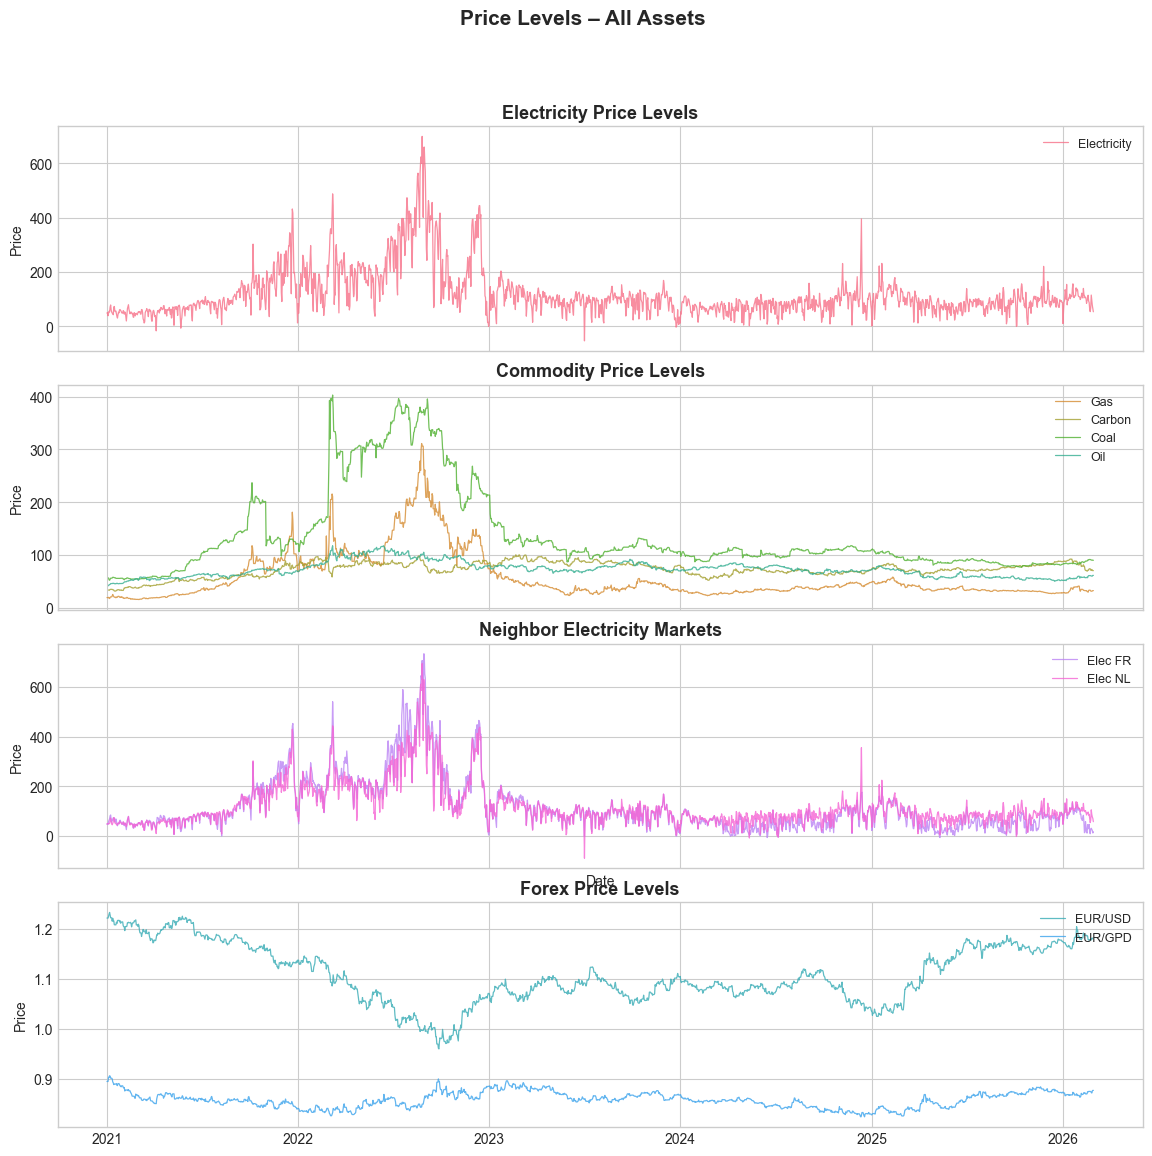

In [480]:
assets = {
    "Electricity": price_history_electricity,
    "Gas": price_history_gas_monthly1,
    "Carbon": price_history_carbon,
    "Coal": price_history_coal,
    "Oil": price_history_oil,
    "EUR/USD": price_history_EURUSD,
    "EUR/GPD": price_history_EURGPD,
    "Elec FR": price_history_elec_fr,
    "Elec NL": price_history_elec_nl,
}

price_levels = {}
for name, df in assets.items():
    price_levels[name] = df.sort_values("date").set_index("date")["price"]

price_df = pd.DataFrame(price_levels)

commodity_names  = ["Gas", "Carbon", "Coal", "Oil"]
neighbor_names   = ["Elec FR", "Elec NL"]
forex_names      = ["EUR/USD", "EUR/GPD"]

palette = sns.color_palette("husl", len(assets))
color_map = dict(zip(assets.keys(), palette))

fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True,
                         gridspec_kw={"hspace": 0.15})

axes[0].plot(price_df.index, price_df["Electricity"],
                 label="Electricity", color=color_map["Electricity"], alpha=0.8, linewidth=0.9)

for name in commodity_names:
    axes[1].plot(price_df.index, price_df[name],
                 label=name, color=color_map[name], alpha=0.8, linewidth=0.9)

for name in neighbor_names:
    axes[2].plot(price_df.index, price_df[name],
                 label=name, color=color_map[name], alpha=0.8, linewidth=0.9)

for name in forex_names:
    axes[3].plot(price_df.index, price_df[name],
                 label=name, color=color_map[name], alpha=0.8, linewidth=0.9)

for ax, title in zip(axes, ["Electricity Price Levels", "Commodity Price Levels", "Neighbor Electricity Markets",
                             "Forex Price Levels"]):
    ax.set_ylabel("Price")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.legend(loc="upper right", framealpha=0.9, fontsize=9)

axes[2].set_xlabel("Date")
fig.suptitle("Price Levels – All Assets", fontsize=15, fontweight="bold", y=0.97)
plt.tight_layout()
plt.show()

## Metrics

In [481]:
# ADF
from statsmodels.tsa.stattools import adfuller

In [482]:
def _adf_test(series, name=""):
    result = adfuller(series.dropna(), autolag='AIC')
    
    output = {
        "variable": name,
        "adf_stat": result[0],
        "p_value": result[1],
        "lags": result[2],
        "n_obs": result[3],
    }
    
    return output

In [483]:
print(f'Electricity: {_adf_test(price_history_electricity["return"], name="Electricity")["p_value"] < 0.05}')

print(f'Gas: {_adf_test(price_history_gas_monthly1["return"], name="Gas")["p_value"] < 0.05}')
print(f'Carbon: {_adf_test(price_history_carbon["return"], name="Carbon")["p_value"] < 0.05}')
print(f'Coal: {_adf_test(price_history_coal["return"], name="Coal")["p_value"] < 0.05}')
print(f'Oil: {_adf_test(price_history_oil["return"], name="Oil")["p_value"] < 0.05}')

print(f'Elec FR: {_adf_test(price_history_elec_fr["return"], name="Elec FR")["p_value"] < 0.05}')
print(f'Elec NL: {_adf_test(price_history_elec_nl["return"], name="Elec NL")["p_value"] < 0.05}')

print(f'EUR/USD: {_adf_test(price_history_EURUSD["return"], name="EUR/USD")["p_value"] < 0.05}')
print(f'EUR/GPD: {_adf_test(price_history_EURGPD["return"], name="EUR/GPD")["p_value"] < 0.05}')


Electricity: True
Gas: True
Carbon: True
Coal: True
Oil: True
Elec FR: True
Elec NL: True
EUR/USD: True
EUR/GPD: True


In [484]:
# Granger Causality
from statsmodels.tsa.stattools import grangercausalitytests

In [485]:
def granger_test(x, y, max_lag=5):
    """
    Tests whether x Granger-causes y
    """
    import pandas as pd
    
    df = pd.concat([y, x], axis=1)
    df.columns = ['y', 'x']
    df = df.dropna()
    
    results = grangercausalitytests(df, maxlag=max_lag, verbose=False)
    
    output = []
    
    for lag in range(1, max_lag + 1):
        p_value = results[lag][0]['ssr_ftest'][1]
        
        output.append({
            "lag": lag,
            "p_value": p_value
        })
    
    return pd.DataFrame(output)

In [486]:
print("Gas -> Electricity")
print(granger_test(price_history_gas_monthly1['return'], price_history_electricity['return']))

print("Carbon -> Electricity")
print(granger_test(price_history_carbon['return'], price_history_electricity['return']))

print("Coal -> Electricity")
print(granger_test(price_history_coal['return'], price_history_electricity['return']))

print("Oil -> Electricity")
print(granger_test(price_history_oil['return'], price_history_electricity['return']))

print("Elec FR -> Electricity")
print(granger_test(price_history_elec_fr['return'], price_history_electricity['return']))

print("Elec NL -> Electricity")
print(granger_test(price_history_elec_nl['return'], price_history_electricity['return']))

print("EUR/USD -> Electricity")
print(granger_test(price_history_EURUSD['return'], price_history_electricity['return']))

print("EUR/GPD -> Electricity")
print(granger_test(price_history_EURGPD['return'], price_history_electricity['return']))

Gas -> Electricity
   lag   p_value
0    1  0.220421
1    2  0.066855
2    3  0.025308
3    4  0.034496
4    5  0.043648
Carbon -> Electricity
   lag   p_value
0    1  0.560936
1    2  0.754159
2    3  0.914889
3    4  0.981291
4    5  0.980771
Coal -> Electricity
   lag   p_value
0    1  0.825838
1    2  0.741492
2    3  0.818635
3    4  0.848904
4    5  0.224675
Oil -> Electricity
   lag   p_value
0    1  0.043315
1    2  0.065738
2    3  0.140680
3    4  0.351193
4    5  0.457943
Elec FR -> Electricity
   lag   p_value
0    1  0.000002
1    2  0.000035
2    3  0.000020
3    4  0.000066
4    5  0.000139
Elec NL -> Electricity
   lag   p_value
0    1  0.000488
1    2  0.000260
2    3  0.000812
3    4  0.002869
4    5  0.000099
EUR/USD -> Electricity
   lag   p_value
0    1  0.517475
1    2  0.040228
2    3  0.075746
3    4  0.131905
4    5  0.067704
EUR/GPD -> Electricity
   lag   p_value
0    1  0.986665
1    2  0.661969
2    3  0.730655
3    4  0.601537
4    5  0.757641


In [487]:
price = price_history_electricity['price']

price_smooth = price.rolling(7).mean()

high_level = price_smooth > price_smooth.quantile(0.8)

# Persistence: at least 4 of the last 7 days above the threshold
shock = high_level.rolling(7).sum() >= 4
normal = ~shock

valid = price.notna()
shock_idx = shock & valid
normal_idx = normal & valid

price_history_electricity['vol_regime'] = np.where(shock, 'high', 'low')

# Identify contiguous regime blocks (Granger needs consecutive observations)
regime_series = price_history_electricity['vol_regime']
block_id = (regime_series != regime_series.shift()).cumsum()
price_history_electricity['regime_block'] = block_id


def _contiguous_regime_panels(electricity_df, other_asset_df, regime,
                              other_name="other", min_block_len=30):
    """Merge contiguous blocks of a given regime with the other asset.
    Prefer long contiguous runs, but fall back to all available matches if needed."""
    other = other_asset_df[["date", "return"]].rename(columns={"return": other_name})
    regime_df = electricity_df[electricity_df["vol_regime"] == regime].copy()

    long_panels = []
    all_panels = []
    for _, block in regime_df.groupby("regime_block"):
        merged = (
            block[["date", "return"]]
            .rename(columns={"return": "elec"})
            .merge(other, on="date", how="inner")
            .dropna(subset=["elec", other_name])
            .sort_values("date")
        )
        if merged.empty:
            continue

        panel = merged[["elec", other_name]]
        all_panels.append(panel)
        if len(merged) >= min_block_len:
            long_panels.append(panel)

    if long_panels:
        return pd.concat(long_panels, ignore_index=True)
    if all_panels:
        return pd.concat(all_panels, ignore_index=True)
    return pd.DataFrame(columns=["elec", other_name])


def granger_by_regime(
    electricity_df,
    other_asset_df,
    other_name="other",
    max_lag=5,
    min_block_len=30,
):
    data_high = _contiguous_regime_panels(
        electricity_df, other_asset_df, "high", other_name, min_block_len
    )
    data_low = _contiguous_regime_panels(
        electricity_df, other_asset_df, "low", other_name, min_block_len
    )

    results = {}
    for label, data in [("high_vol", data_high), ("low_vol", data_low)]:
        if len(data) > max_lag + 1:
            results[label] = granger_test(data[other_name], data["elec"], max_lag=max_lag)
        else:
            results[label] = f"Insufficient data ({len(data)} obs)"

    print("High volatility —", other_name, "-> elec:\n", results["high_vol"], "\n")
    print("Low volatility —", other_name, "-> elec:\n", results["low_vol"])
    
    return results

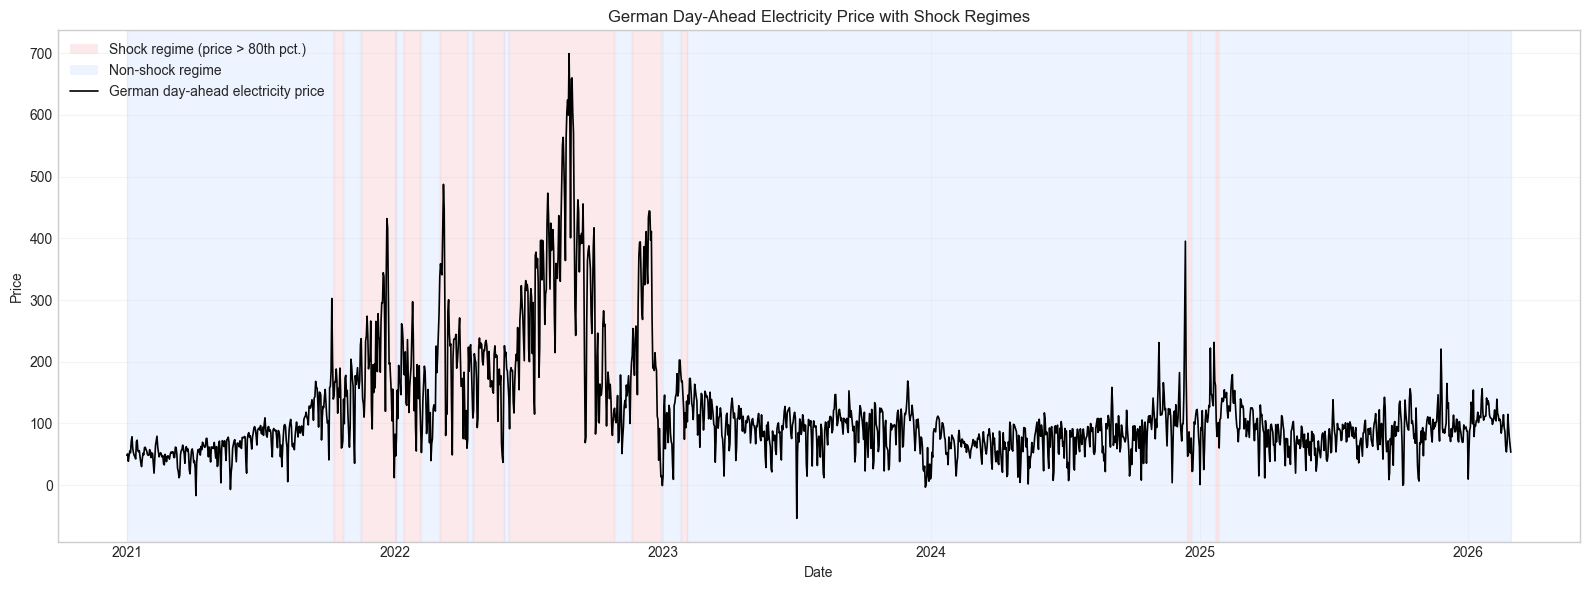

In [488]:
# Regime visualization on German day-ahead electricity price
regime_plot_df = (
    price_history_electricity[["date", "price", "vol_regime"]]
    .dropna(subset=["date", "price", "vol_regime"])
    .sort_values("date")
    .copy()
)

regime_plot_df["regime_block"] = (
    regime_plot_df["vol_regime"] != regime_plot_df["vol_regime"].shift()
).cumsum()

fig, ax = plt.subplots(figsize=(16, 6))

for _, block in regime_plot_df.groupby("regime_block"):
    regime = block["vol_regime"].iloc[0]
    color = "#f5c2c7" if regime == "high" else "#cfe2ff"
    ax.axvspan(block["date"].iloc[0], block["date"].iloc[-1], color=color, alpha=0.35)

ax.plot(
    regime_plot_df["date"],
    regime_plot_df["price"],
    color="black",
    linewidth=1.2,
    label="German day-ahead electricity price",
)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#f5c2c7", edgecolor="none", alpha=0.35, label="Shock regime (price > 80th pct.)"),
    Patch(facecolor="#cfe2ff", edgecolor="none", alpha=0.35, label="Non-shock regime"),
]

ax.set_title("German Day-Ahead Electricity Price with Shock Regimes")
ax.set_xlabel("Date")
ax.set_ylabel("Price")
ax.legend(handles=legend_handles + [ax.lines[0]], loc="upper left")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [489]:
results_gas_monthly1 = granger_by_regime(
    price_history_electricity,
    price_history_gas_monthly1,
    other_name="gas",
    max_lag=5,
)

High volatility — gas -> elec:
    lag   p_value
0    1  0.116199
1    2  0.011447
2    3  0.003082
3    4  0.002485
4    5  0.001420 

Low volatility — gas -> elec:
    lag   p_value
0    1  0.316151
1    2  0.153294
2    3  0.266560
3    4  0.367508
4    5  0.511966


In [490]:
results_carbon = granger_by_regime(
    price_history_electricity,
    price_history_carbon,
    other_name="carbon",
    max_lag=5,
)

High volatility — carbon -> elec:
    lag   p_value
0    1  0.960429
1    2  0.505869
2    3  0.360107
3    4  0.280675
4    5  0.217851 

Low volatility — carbon -> elec:
    lag   p_value
0    1  0.991165
1    2  0.428450
2    3  0.676953
3    4  0.804263
4    5  0.403797


In [491]:
results_coal = granger_by_regime(
    price_history_electricity,
    price_history_coal,
    other_name="coal",
    max_lag=5,
)

High volatility — coal -> elec:
    lag   p_value
0    1  0.148822
1    2  0.228858
2    3  0.258270
3    4  0.194814
4    5  0.176281 

Low volatility — coal -> elec:
    lag   p_value
0    1  0.341253
1    2  0.036583
2    3  0.053272
3    4  0.140603
4    5  0.140464


In [492]:
results_oil = granger_by_regime(
    price_history_electricity,
    price_history_oil,
    other_name="oil",
    max_lag=5,
)

High volatility — oil -> elec:
    lag   p_value
0    1  0.391988
1    2  0.203988
2    3  0.406525
3    4  0.087170
4    5  0.018276 

Low volatility — oil -> elec:
    lag   p_value
0    1  0.632571
1    2  0.772022
2    3  0.571478
3    4  0.605781
4    5  0.795581


In [493]:
results_EURUSD = granger_by_regime(
    price_history_electricity,
    price_history_EURUSD,
    other_name="EURUSD",
    max_lag=5,
)

High volatility — EURUSD -> elec:
    lag   p_value
0    1  0.858884
1    2  0.017763
2    3  0.013794
3    4  0.036257
4    5  0.016104 

Low volatility — EURUSD -> elec:
    lag   p_value
0    1  0.448927
1    2  0.247042
2    3  0.427343
3    4  0.272880
4    5  0.311622


In [494]:
results_EURGPD = granger_by_regime(
    price_history_electricity,
    price_history_EURGPD,
    other_name="EURGPD",
    max_lag=5,
)

High volatility — EURGPD -> elec:
    lag   p_value
0    1  0.812809
1    2  0.889780
2    3  0.621112
3    4  0.776558
4    5  0.893844 

Low volatility — EURGPD -> elec:
    lag   p_value
0    1  0.831943
1    2  0.766918
2    3  0.884888
3    4  0.873732
4    5  0.842728


In [495]:
results_elec_fr = granger_by_regime(
    price_history_electricity,
    price_history_elec_fr,
    other_name="elec_fr",
    max_lag=5,
)

High volatility — elec_fr -> elec:
    lag   p_value
0    1  0.001781
1    2  0.000197
2    3  0.000689
3    4  0.001269
4    5  0.001046 

Low volatility — elec_fr -> elec:
    lag   p_value
0    1  0.000008
1    2  0.000193
2    3  0.000141
3    4  0.000328
4    5  0.000979


In [496]:
results_elec_nl = granger_by_regime(
    price_history_electricity,
    price_history_elec_nl,
    other_name="elec_nl",
    max_lag=5,
)

High volatility — elec_nl -> elec:
    lag       p_value
0    1  4.310237e-07
1    2  4.724655e-07
2    3  1.066818e-06
3    4  1.222180e-06
4    5  1.455587e-06 

Low volatility — elec_nl -> elec:
    lag   p_value
0    1  0.001070
1    2  0.001022
2    3  0.003332
3    4  0.007125
4    5  0.000180


## Conclusion